# ARM KAZR Cloud Persistence Project: Analysis of the Persistence Model

**Alec Blevins — STA 496, Fall 2026**

## Purpose

Notebook 09, `09_modeling.ipynb`, compared models. Here, we will explain the chosen model (HGB, 20 min, Persistence): where it works, where it fails, and what that implies for the next step. 

**Rules**
- Same folds and embargo as 09. Nothing here changes the model or the threshold chosen in 09. Test is used for reporting purposes only. 

| Step | Question |
|---|---|
| 1. Setup | Reproduce the 09 model exactly |
| 2. Operating points | What precision do we get at a given recall, and does it transfer to test? |
| 3. Lead time | Is the model better at imminent endings than distant ones? |
| 4. Long clouds | Is the weakness on old clouds a feature limit or a fitting limit? |
| 5. Importance | Which feature groups carry the skill, and does that differ by cloud age? |



## 1. Library Imports & Setup

In [1]:
#Lib import
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

#Path to project root containing ARM_DATA/2024-2025
_start = Path.cwd().resolve()
PROJECT_ROOT = next(c for c in [_start, *_start.parents] if (c / "ARM_DATA" / "2024-2025").is_dir())
df = pd.read_parquet(PROJECT_ROOT / "ARM_DATA" / "2024-2025" / "modeling" / "modeling_persistence_20min_20s.parquet")

# Define features and target
FEATURES = [c for c in df.columns if c not in {"current_state", "target", "fold"}]
df["y"] = (df.target == 0).astype(int)                      # 1 = dissolved
tr, va, te = (df[df.fold == k] for k in ["train", "val", "test"])

#Helper function from before
def best_f1_threshold(y, p): 
    """Compute the threshold that maximizes the F1 score."""
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr[:-1] * rc[:-1] / np.clip(pr[:-1] + rc[:-1], 1e-12, None)
    return float(th[np.argmax(f1)])

#Define and fit HistGradientBoostingClassifier
hgb = HistGradientBoostingClassifier(max_depth=6, learning_rate=0.05, max_iter=300,
                                     early_stopping=True, validation_fraction=0.1, random_state=0)
hgb.fit(tr[FEATURES], tr.y)
p_va, p_te = hgb.predict_proba(va[FEATURES])[:, 1], hgb.predict_proba(te[FEATURES])[:, 1]
thr = best_f1_threshold(va.y.values, p_va)

# must match notebook 09: val PR-AUC 0.781, test PR-AUC 0.646, thr 0.315
print(round(average_precision_score(va.y, p_va), 3), round(average_precision_score(te.y, p_te), 3), round(thr, 3))

0.781 0.646 0.315


## 2. Operating Points
A single F1 cutoff hides the trade-off. Here, we will chose the threshold on **validation** to hit a target recall, then apply it unchanged to the test. 

If the validation-chosen threshold gives a different recall on test, the operating point does not transfer. 

,target_recall,thr,val_recall,val_precision,val_alarm_rate,test_recall,test_precision,test_alarm_rate
0,0.5,0.638,0.5,0.796,0.205,0.440,0.706,0.114
1,0.6,0.549,0.6,0.749,0.262,0.519,0.666,0.143
2,0.7,0.443,0.7,0.698,0.328,0.608,0.617,0.180
3,0.8,0.329,0.8,0.651,0.402,0.701,0.551,0.233
4,0.9,0.197,0.9,0.583,0.504,0.816,0.474,0.315


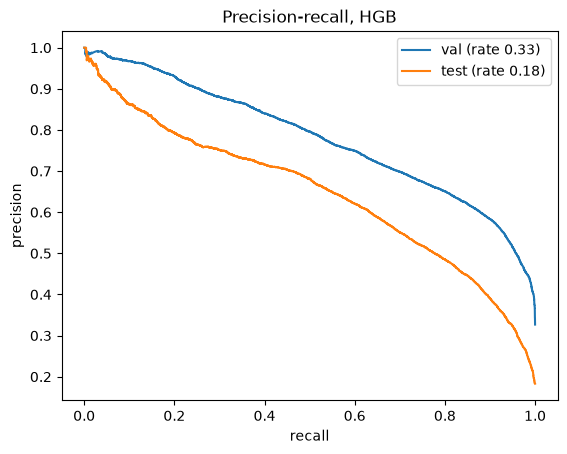

In [2]:
pr, rc, th = precision_recall_curve(va.y.values, p_va) # compute precision-recall curve on validation set
rows = []

# Compute thresholds for different target recall levels on the validation set
for target in [0.5, 0.6, 0.7, 0.8, 0.9]:
    t = th[np.flatnonzero(rc[:-1] >= target)[-1]]     # highest threshold that still reaches the target recall on val
    row = dict(target_recall=target, thr=t)
    for name, d, p in [("val", va, p_va), ("test", te, p_te)]: # evaluate on both validation and test sets
        yhat = p >= t
        tp = (yhat & (d.y.values == 1)).sum() # true positives
        row |= {f"{name}_recall": tp / d.y.sum(), f"{name}_precision": tp / max(yhat.sum(), 1), # compute recall, precision, and alarm rate
                f"{name}_alarm_rate": yhat.mean()}
    rows.append(row)
display(pd.DataFrame(rows).round(3))

fig, ax = plt.subplots() #Plot precision-recall curves for validation and test sets
for name, d, p in [("val", va, p_va), ("test", te, p_te)]:
    pr_, rc_, _ = precision_recall_curve(d.y.values, p)
    ax.plot(rc_, pr_, label=f"{name} (rate {d.y.mean():.2f})")
ax.set(xlabel="recall", ylabel="precision", title="Precision-recall, HGB"); ax.legend(); plt.show()